### Radial Basis Function Optimization (RBFOpt) Test on the Dynamic Control Optimization Problem

This notebook demonstrates the application of **Radial Basis Function Optimization (RBFOpt)** to a **Dynamic Control Optimization** problem.  
The notebook includes visualizations of the optimization trajectory and the best solution identified at each iteration.
When using **RBFOpt** for this problem, **BONMIN** is used as the **MINLP** solver and **IPOPT** is used as the **NLP** solver.
The optimization trajectory produced by **RBFOpt** is also provided as a **GIF file** to illustrate how the search progresses over the course of the iterations.  
In addition, it presents plots comparing the objective-value trajectories of several optimization algorithms, including **Logic-based Discrete-Steepest Descent Algorithm (LD-SDA)** and **RBFOpt**, to evaluate and compare their performance on the Dynamic Control Optimization problem.

In [1]:
%%capture
import rbfopt
import matplotlib.pyplot as plt
import numpy as np

In [2]:
minlp_solver_path=''
nlp_solver_path=''

In [4]:
feasible_solution = {
    (1, 2): -197.14013122689622,
    (1, 3): -206.36041265432806,
    (1, 4): -212.00878719112268,
    (1, 5): -207.62611633572016,
    (1, 6): -196.93118428995865,
    (1, 7): -178.63847525562682,
    (1, 8): -146.87850122234687,
    (1, 9): -87.5338894428716,
    (2, 3): -117.07438084784795,
    (2, 4): -137.1797042946188,
    (2, 5): -192.870848809807,
    (2, 6): -192.88392569521721,
    (2, 7): -175.94473700875903,
    (2, 8): -144.71276519403037,
    (2, 9): -85.82696130620648,
    (3, 4): -77.19743879461578,
    (3, 5): -88.41538101128177,
    (3, 6): -119.38309938589616,
    (3, 7): -170.89539354574913,
    (3, 8): -141.82503814335138,
    (3, 9): -83.55206301486514,
    (4, 5): -55.81190616713566,
    (4, 6): -62.4732860007934,
    (4, 7): -77.86237831841856,
    (4, 8): -135.07901900226858,
    (4, 9): -80.51745201314861,
    (5, 6): -43.41238657553521,
    (5, 7): -47.28320969606174,
    (5, 8): -54.212220237141665,
    (5, 9): -66.30029047415469,
    (6, 7): -36.01889379296989,
    (6, 8): -37.96970292827284,
    (6, 9): -39.58228460866401,
    (7, 8): -31.679373632369185,
    (7, 9): -32.196321090299925,
    (8, 9): -29.327202909495576,
    (9, 9): -28.596739202011523,
}

In [5]:
def obj_funct(x):
    # RBFOpt requires the objective function to return a tuple (obj_value, constraint_values)
    x_tuple = tuple(int(xi) for xi in x)
    if x_tuple in feasible_solution:
        return (feasible_solution[x_tuple])
    else:
        return (1e6)  # large penalty for infeasible solutions

# Test
obj_funct([1,2])

-197.14013122689622

In [6]:
# Set up the black-box for a 2D problem with integer variables.
# We use the determined bounds and mark both variables as integer ("I").
black_box = rbfopt.RbfoptUserBlackBox(
    2,
    np.array([1, 2]),    # lower bounds for x and y
    np.array([9, 9]),  # upper bounds for x and y
    np.array(["I", "I"]),# both variables are integers
    obj_funct
)

# Configure optimization settings.
settings = rbfopt.RbfoptSettings(
    max_evaluations=12,  # maximum number of evaluations
    minlp_solver_path=minlp_solver_path, # path to the MINLP solver
    nlp_solver_path=nlp_solver_path, # path to the NLP solver
    algorithm='MSRSM',   # optimization algorithm variant
    rbf='auto',           # allow automatic RBF selection
    global_search_method = 'solver',  # options = ['sampling', 'genetic', 'solver']
)

# Create the optimization algorithm instance.
alg = rbfopt.RbfoptAlgorithm(settings, black_box)

# Run the optimization.
best_val, best_point, itercount, evalcount, fast_evalcount = alg.optimize()

print("Optimization completed.")
print("Best objective value found:", best_val)
print("At lattice point (rounded):", [int(round(v)) for v in best_point])
print("Iterations:", itercount, "Function evaluations:", evalcount)

  Iter  Cycle  Action             Objective value      Time      Gap
  ----  -----  ------             ---------------      ----      ---
     0      0  Initialization          -28.596739      0.01   100.00  
     0      0  Initialization      1000000.000000      0.02   100.00  
     0      0  Initialization          -43.412387      0.02   100.00 *
     0      0  GlobalStep              -87.533889      0.29   100.00 *
     1      0  GlobalStep              -83.552063      1.37   100.00  
     2      0  GlobalStep              -85.826961      1.80   100.00  
     3      0  GlobalStep             -146.878501      2.34   100.00 *
     4      0  GlobalStep             -178.638475      2.63   100.00 *
     5      0  LocalStep              -196.931184      2.86   100.00 *
     6      1  GlobalStep             -207.626116      3.14   100.00 *
     7      1  GlobalStep             -212.008787      3.59   100.00 *
     8      1  GlobalStep             -192.870849      4.13   100.00  
Summary: i

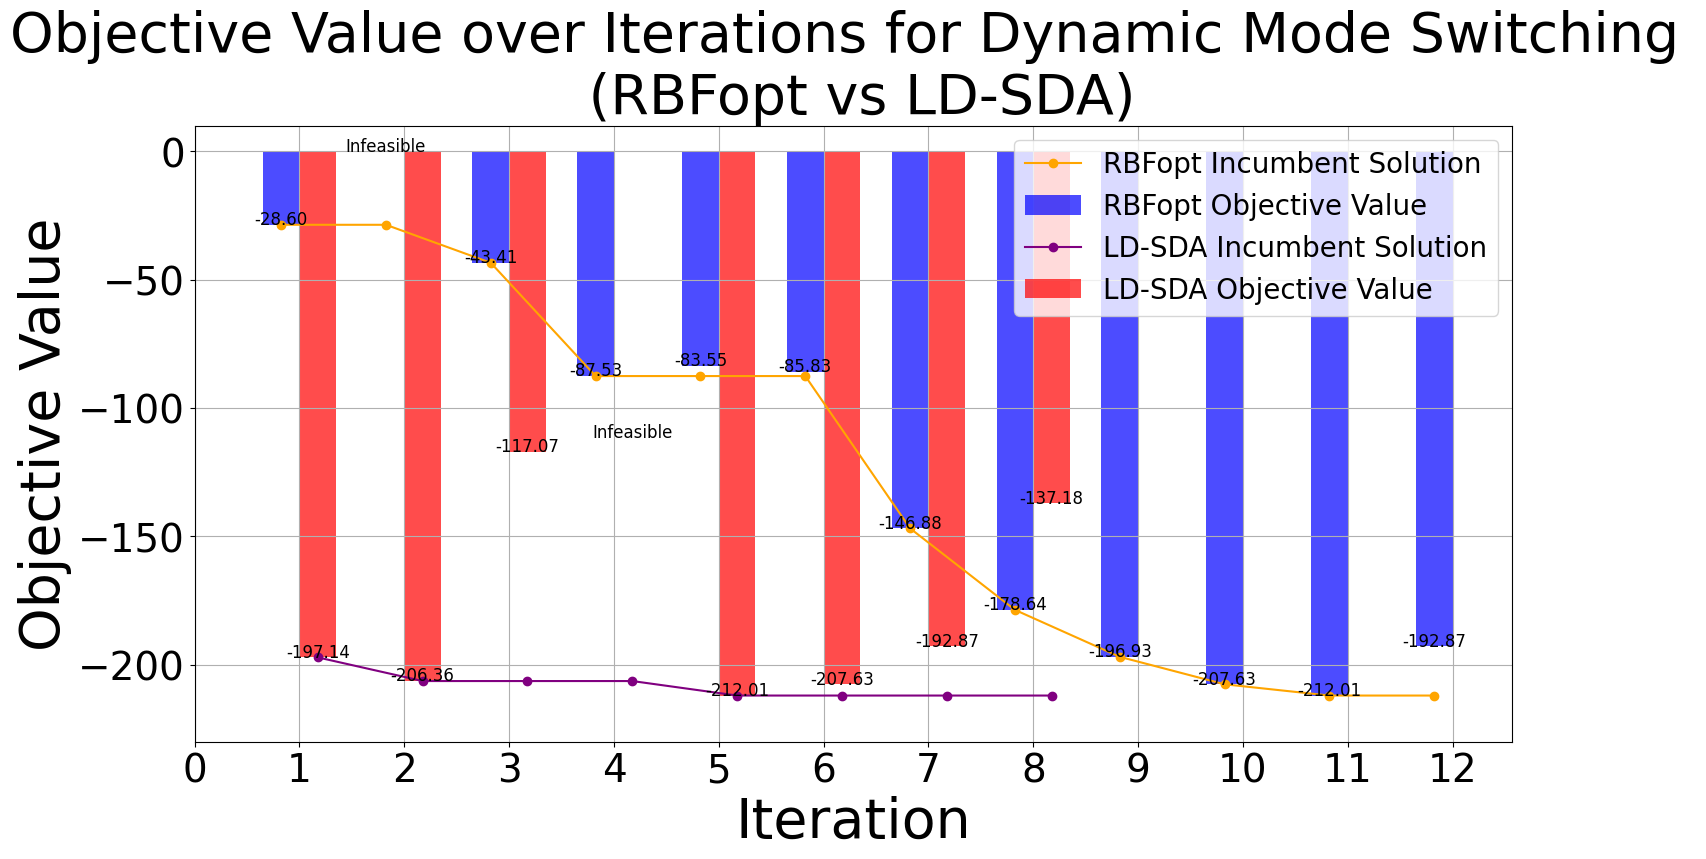

In [7]:
# Trajectory: 
# Iter   0 Obj      -28.596739 Point [9. 9.]
# Iter   1 Obj  1000000.000000 Point [2. 2.]
# Iter   2 Obj      -43.412387 Point [5. 6.]
# Iter   3 Obj      -87.533889 Point [1. 9.]
# Iter   4 Obj      -83.552063 Point [3. 9.]
# Iter   5 Obj      -85.826961 Point [2. 9.]
# Iter   6 Obj     -146.878501 Point [1. 8.]
# Iter   7 Obj     -178.638475 Point [1. 7.]
# Iter   8 Obj     -196.931184 Point [1. 6.]
# Iter   9 Obj     -207.626116 Point [1. 5.]
# Iter  10 Obj     -212.008787 Point [1. 4.]
# Iter  11 Obj     -192.870849 Point [2. 5.]

feasible_solution = {
    (1, 2): -197.14013122689622,
    (1, 3): -206.36041265432806,
    (1, 4): -212.00878719112268,
    (1, 5): -207.62611633572016,
    (1, 6): -196.93118428995865,
    (1, 7): -178.63847525562682,
    (1, 8): -146.87850122234687,
    (1, 9): -87.5338894428716,
    (2, 3): -117.07438084784795,
    (2, 4): -137.1797042946188,
    (2, 5): -192.870848809807,
    (2, 6): -192.88392569521721,
    (2, 7): -175.94473700875903,
    (2, 8): -144.71276519403037,
    (2, 9): -85.82696130620648,
    (3, 4): -77.19743879461578,
    (3, 5): -88.41538101128177,
    (3, 6): -119.38309938589616,
    (3, 7): -170.89539354574913,
    (3, 8): -141.82503814335138,
    (3, 9): -83.55206301486514,
    (4, 5): -55.81190616713566,
    (4, 6): -62.4732860007934,
    (4, 7): -77.86237831841856,
    (4, 8): -135.07901900226858,
    (4, 9): -80.51745201314861,
    (5, 6): -43.41238657553521,
    (5, 7): -47.28320969606174,
    (5, 8): -54.212220237141665,
    (5, 9): -66.30029047415469,
    (6, 7): -36.01889379296989,
    (6, 8): -37.96970292827284,
    (6, 9): -39.58228460866401,
    (7, 8): -31.679373632369185,
    (7, 9): -32.196321090299925,
    (8, 9): -29.327202909495576,
    (9, 9): -28.596739202011523,
}

rbfopt_iterations = [(1, -28.596739202011523, [9.0, 9.0]),
                     (2, float('inf'), [2.0, 2.0]),
                     (3, -43.41238657553521, [5.0, 6.0]),
                     (4, -87.5338894428716, [1.0, 9.0]),
                     (5, -83.55206301486514, [3.0, 9.0]),
                     (6, -85.82696130620648, [2.0, 9.0]),
                     (7, -146.87850122234687, [1.0, 8.0]),
                     (8, -178.63847525562682, [1.0, 7.0]),
                     (9, -196.93118428995865, [1.0, 6.0]),
                     (10, -207.62611633572016, [1.0, 5.0]),
                     (11, -212.00878719112268, [1.0, 4.0]),
                     (12, -192.870848809807, [2.0, 5.0])]


ldsda_iterations = [(1, -197.14013122689622, [1, 2]),
                    (2, -206.36041265432806, [1, 3]),
                    (3, -117.07438084784795, [2, 3]),
                    (4, float('inf'), [2, 2]),
                    (5, -212.00878719112268, [1, 4]),
                    (6, -207.62611633572016, [1, 5]),
                    (7, -192.870848809807, [2, 5]),
                    (8, -137.1797042946188, [2, 4])]

# Extract iteration indices and objective values
RBFopt_indices = [pt[0] for pt in rbfopt_iterations]
RBFopt_obj = [pt[1] for pt in rbfopt_iterations]

LDSDA_indices = [pt[0] for pt in ldsda_iterations]
LDSDA_obj = [pt[1] for pt in ldsda_iterations]

# Calculate best-so-far (ladder plot) for each method
RBFopt_best = [min(RBFopt_obj[:i+1]) for i in range(len(RBFopt_obj))]
LDSDA_best = [min(LDSDA_obj[:i+1]) for i in range(len(LDSDA_obj))]

# For annotations of infeasible bars, determine a fixed y-position
ldsda_feasible = [obj for obj in LDSDA_obj if not np.isinf(obj)]
ldsda_feasible_max = max(ldsda_feasible) if ldsda_feasible else 1

fig, ax = plt.subplots(figsize=(17, 8))
bar_width = 0.35

# Convert indices to numpy arrays for arithmetic
RBFopt_x = np.array(RBFopt_indices, dtype=float)
LDSDA_x = np.array(LDSDA_indices, dtype=float)

# Plot RBFopt bars (shift left)
bars_rbf = ax.bar(RBFopt_x - bar_width/2, RBFopt_obj, width=bar_width,
                  color='blue', alpha=0.7, label='RBFopt Objective Value')
# Annotate RBFopt bars
for x, obj in zip(RBFopt_x, RBFopt_obj):
    if np.isinf(obj):
        ax.text(x - bar_width/2, 0, 'Infeasible', fontsize=12, color='black', ha='center')
    else:
        ax.text(x - bar_width/2, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Plot RBFopt best-so-far (ladder) and store its handle
line_rbf, = ax.plot(RBFopt_x - bar_width/2, RBFopt_best, marker='o', linestyle='-', color='orange',
                    label='RBFopt Incumbent Solution')

# Plot LD-SDA bars (shift right)
bars_ldsda = ax.bar(LDSDA_x + bar_width/2, LDSDA_obj, width=bar_width,
                    color='red', alpha=0.7, label='LD-SDA Objective Value')
# Annotate LD-SDA bars
for x, obj in zip(LDSDA_x, LDSDA_obj):
    if np.isinf(obj):
        ax.text(x + bar_width/2, ldsda_feasible_max * 0.95, 'Infeasible', fontsize=12, color='black', ha='center')
    else:
        ax.text(x + bar_width/2, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Plot LD-SDA best-so-far (ladder) and store its handle
line_ldsda, = ax.plot(LDSDA_x + bar_width/2, LDSDA_best, marker='o', linestyle='-', color='purple',
                      label='LD-SDA Incumbent Solution')

# Now manually set the legend order by specifying handles in the desired sequence
ax.legend(
    [line_rbf, bars_rbf, line_ldsda, bars_ldsda], 
    [
        'RBFopt Incumbent Solution',   # 1
        'RBFopt Objective Value',      # 2
        'LD-SDA Incumbent Solution',   # 3
        'LD-SDA Objective Value'       # 4
    ],
    fontsize=20
)

# Labeling and styling
ax.set_xlabel('Iteration', fontsize=40)
ax.set_ylabel('Objective Value', fontsize=40)
ax.set_title('Objective Value over Iterations for Dynamic Mode Switching \n (RBFopt vs LD-SDA)', fontsize=40)
ax.grid(True)

# Set x-axis ticks
max_iter = max(max(RBFopt_indices), max(LDSDA_indices))
ax.set_xticks(np.arange(0, max_iter + 1, 1))
ax.tick_params(axis='y', labelsize=28)
ax.tick_params(axis='x', labelsize=28)
ax.set_ylim(-230, 10)

plt.show()

MovieWriter ffmpeg unavailable; using Pillow instead.


('gif/dynamic_rbfopt_iteration1_start.gif', None)

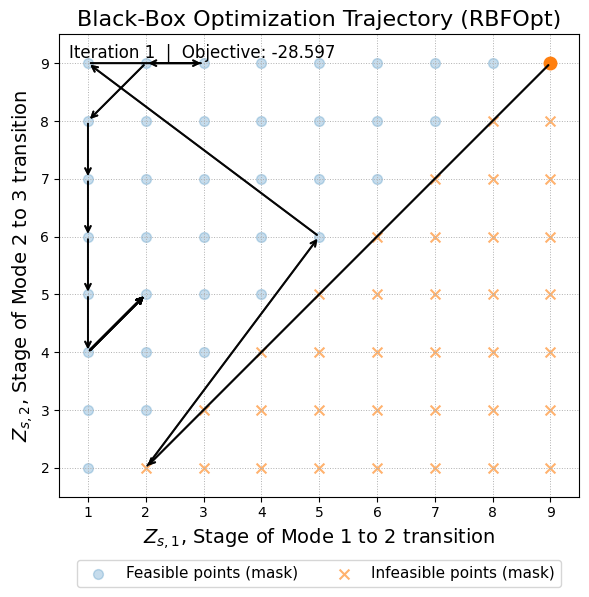

In [8]:
# Recreate final animation:
# - Start iteration numbering from 1
# - Keep all features: feasible/infeasible masks, arrows, pause at final, yellow final dot

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

rbfopt_iterations = [(1, -28.596739202011523, [9.0, 9.0]),
                     (2, float('inf'), [2.0, 2.0]),
                     (3, -43.41238657553521, [5.0, 6.0]),
                     (4, -87.5338894428716, [1.0, 9.0]),
                     (5, -83.55206301486514, [3.0, 9.0]),
                     (6, -85.82696130620648, [2.0, 9.0]),
                     (7, -146.87850122234687, [1.0, 8.0]),
                     (8, -178.63847525562682, [1.0, 7.0]),
                     (9, -196.93118428995865, [1.0, 6.0]),
                     (10, -207.62611633572016, [1.0, 5.0]),
                     (11, -212.00878719112268, [1.0, 4.0]),
                     (12, -192.870848809807, [2.0, 5.0])]


rbf_x = [p[2][0] for p in rbfopt_iterations]
rbf_y = [p[2][1] for p in rbfopt_iterations]
rbf_obj = [p[1] for p in rbfopt_iterations]

# For dynamic cases
opt_idx = len(rbf_x) - 2
last_idx = len(rbf_x) - 1

# Feasible/infeasible masks
infeasible_mask = [  (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9,8),
                     (8, 2), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7),(8, 8),
                     (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7),
                     (6, 2), (6, 3), (6, 4), (6, 5), (6 ,6),
                     (5, 2), (5, 3), (5, 4), (5, 5),
                     (4, 2), (4, 3), (4, 4),
                     (3, 2), (3, 3),
                     (2, 2)
]
feasible_mask = [(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9),
    (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9),
    (3, 4), (3, 5), (3, 6), (3, 7), (3, 8), (3, 9),
    (4, 5), (4, 6), (4, 7), (4, 8), (4, 9),
    (5, 6), (5, 7), (5, 8), (5, 9),
    (6, 7), (6, 8), (6, 9),
    (7, 8), (7, 9),
    (8, 9),
    (9, 9) ]

fig, ax = plt.subplots(figsize=(6.8, 6.8))
ax.set_aspect('equal', 'box')
ax.set_xlim(0.5, 9.5)
ax.set_ylim(1.5, 9.5)
ax.set_xticks(range(1, 10))
ax.set_yticks(range(2, 10))
ax.grid(True, linestyle=':', linewidth=0.7)
ax.set_xlabel('$Z_{s,1}$, Stage of Mode 1 to 2 transition', fontsize=14)
ax.set_ylabel('$Z_{s,2}$, Stage of Mode 2 to 3 transition', fontsize=14)
ax.set_title('Black-Box Optimization Trajectory (RBFOpt)', fontsize=16)

# Masks
if feasible_mask:
    fx, fy = zip(*feasible_mask)
    ax.scatter(fx, fy, s=50, marker='o', alpha=0.25, label='Feasible points (mask)')
if infeasible_mask:
    ix, iy = zip(*infeasible_mask)
    ax.scatter(ix, iy, s=50, marker='x', alpha=0.6, label='Infeasible points (mask)')

fig.subplots_adjust(bottom=0.20)
ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=True,
    fontsize=11
)

# Trajectory and markers
line, = ax.plot([], [], marker='o', linestyle='-', label='RBFOpt trajectory')
point, = ax.plot([], [], marker='o', markersize=9)
final_point, = ax.plot([], [], marker='o', markersize=14, linestyle='',
                       markeredgecolor='black', markerfacecolor='yellow')
back_line, = ax.plot([], [], linestyle='--', linewidth=1.5)  # dashed "return" segment
text = ax.text(0.02, 0.98, '', transform=ax.transAxes, va='top', fontsize=12)
# ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=True)

arrows = []

def update(k):
    n = len(rbf_x)

    # 1..n (forward play + pause). NO yellow on last sample.
    if k <= n:
        line.set_data(rbf_x[:k], rbf_y[:k])
        point.set_data([rbf_x[k-1]], [rbf_y[k-1]])
        text.set_text(f'Iteration {k}  |  Objective: {rbf_obj[k-1]:.3f}')

        if k >= 2:
            a = ax.annotate("",
                            xy=(rbf_x[k-1], rbf_y[k-1]), xycoords='data',
                            xytext=(rbf_x[k-2], rbf_y[k-2]), textcoords='data',
                            arrowprops=dict(arrowstyle="->", lw=1.4, alpha=0.85))
            arrows.append(a)

        # <<< KEY CHANGE: keep yellow OFF even at the final sample >>>
        final_point.set_data([], [])

        back_line.set_data([], [])
        return line, point, final_point, text, back_line, *arrows

    # n+1: draw dashed return to optimal and show yellow at optimal
    if k == n + 1:
        line.set_data(rbf_x, rbf_y)
        point.set_data([], [])

        back_line.set_data([rbf_x[last_idx], rbf_x[opt_idx]],
                           [rbf_y[last_idx], rbf_y[opt_idx]])
        final_point.set_data([rbf_x[opt_idx]], [rbf_y[opt_idx]])

        text.set_text(
            f'Final sample at Iter {n}. Optimal at Iter {opt_idx+1}  |  Obj: {rbf_obj[opt_idx]:.3f}'
        )
        return line, point, final_point, text, back_line, *arrows

# Frames: play 1..n, then hold at n, then one extra frame (n+1) to return to optimal, then hold
n = len(rbf_x)
frames = list(range(1, n + 1)) + [n] * 8 + [n + 1] + [n + 1] * 6
anim = FuncAnimation(fig, update, frames=frames, interval=1200, blit=False)

gif_path = "gif/dynamic_rbfopt_iteration1_start.gif"
mp4_path = "mp4/dynamic_rbfopt_iteration1_start.mp4"

anim.save(gif_path, writer=PillowWriter(fps=1))
try:
    anim.save(mp4_path, fps=1)
except Exception:
    mp4_path = None

gif_path, mp4_path

In [9]:
# ======================== LD-SDA ANIMATION (GIF) ============================
# Requirements: matplotlib (with Pillow), numpy
# Output: ld_sda.gif
# ---------------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# ------------------------------ GRID MASKS ----------------------------------
infeasible_mask = [  (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9,8),
                     (8, 2), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7),(8, 8),
                     (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7),
                     (6, 2), (6, 3), (6, 4), (6, 5), (6 ,6),
                     (5, 2), (5, 3), (5, 4), (5, 5),
                     (4, 2), (4, 3), (4, 4),
                     (3, 2), (3, 3),
                     (2, 2) ]
feasible_mask = [(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9),
                 (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9),
                 (3, 4), (3, 5), (3, 6), (3, 7), (3, 8), (3, 9),
                 (4, 5), (4, 6), (4, 7), (4, 8), (4, 9),
                 (5, 6), (5, 7), (5, 8), (5, 9),
                 (6, 7), (6, 8), (6, 9),
                 (7, 8), (7, 9),
                 (8, 9),
                 (9, 9) ]

# ------------------------------ ITERATIONS ----------------------------------
# Your dynamic LD-SDA evaluations (iteration, obj, [x,y])
ldsda_iterations = [
    (1, -197.14013122689622, [1, 2]),
    (2, -206.36041265432806, [1, 3]),
    (3, -117.07438084784795, [2, 3]),
    (4, float('inf'),        [2, 2]),
    (5, -212.00878719112268, [1, 4]),
    (6, -207.62611633572016, [1, 5]),
    (7, -192.870848809807,   [2, 5]),
    (8, -137.1797042946188,  [2, 4]),
]

# convenience maps
obj_map = {(float(x), float(y)): float(f) for (k, f, (x, y)) in ldsda_iterations}
# evaluation order of points (must match above list)
eval_order = [tuple(map(float, it[2])) for it in ldsda_iterations]
# best (minimum) objective among the 8
finite_vals = [(pt, v) for pt, v in obj_map.items() if np.isfinite(v)]
best_pt, best_val = min(finite_vals, key=lambda t: t[1]) if finite_vals else (eval_order[0], obj_map[eval_order[0]])

# ------------------------------ EPISODES ------------------------------------
# Neighbor search 1 at (1,2): evaluate (1,2) then (1,3), (2,3), (2,2)
neighbors_A_base    = (1.0, 2.0)
neighbors_A         = [(1.0, 3.0), (2.0, 3.0), (2.0, 2.0)]
neighbors_A_offsets = [(-0.1, 0.0), (0.1, 0.0), (0.0, 0.1)]

# Line search: from (1,3) -> (1,4) and a trial (1,5) (worse) with backtrack
line_from = (1.0, 2.0)
line_to   = [(1.0, 3.0), (1.0, 4.0)]
trial_1   = (1.0, 5.0)  # trial after reaching (1,4)

# Neighbor search 2 at (1,4): evaluate (2,5), (2,4)
neighbors_B_base   = (1.0, 4.0)
neighbors_B        = [(2.0, 5.0), (2.0, 4.0)]
neighbors_B_offset = (-0.1, 0.1)

# --------------------------- ANIMATION SETTINGS -----------------------------
FPS = 2
HOLD_NEIGHBORS = 3
HOLD_BAD = 1
FINAL_HOLD = 6
ARROW_ALPHA = 0.9

# ------------------------------ FIGURE --------------------------------------
fig, ax = plt.subplots(figsize=(6.8, 6.8))
ax.set_aspect('equal', 'box')
ax.set_xlim(0.5, 9.5)
ax.set_ylim(1.5, 9.5)
ax.set_xticks(range(1, 10))
ax.set_yticks(range(2, 10))
ax.grid(True, linestyle=':', linewidth=0.7)
ax.set_xlabel('$Z_{s,1}$, Stage of Mode 1 to 2 transition', fontsize=14)
ax.set_ylabel('$Z_{s,2}$, Stage of Mode 2 to 3 transition', fontsize=14)
ax.set_title('LD-SDA Optimization Trajectory', fontsize=16)

# Masks
if feasible_mask:
    fx, fy = zip(*feasible_mask)
    ax.scatter(fx, fy, s=50, marker='o', alpha=0.25, label='Feasible points (mask)')
if infeasible_mask:
    ix, iy = zip(*infeasible_mask)
    ax.scatter(ix, iy, s=50, marker='x', alpha=0.6, label='Infeasible points (mask)')

fig.subplots_adjust(bottom=0.20)
ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=True,
    fontsize=11
)

# HUD
hud = ax.text(0.02, 0.98, '', transform=ax.transAxes, va='top', fontsize=12, zorder=6)

# ------------------------------ HELPERS -------------------------------------
def draw_neighbor_arrow(start, end, offset=(0,0)):
    sx, sy = start[0] + offset[0], start[1] + offset[1]
    ex, ey = end[0] + offset[0], end[1] + offset[1]
    return [ax.annotate("",
                        xy=(ex, ey), xycoords='data',
                        xytext=(sx, sy), textcoords='data',
                        arrowprops=dict(arrowstyle="->",
                                        linestyle="dotted",
                                        color="red",
                                        lw=2, alpha=ARROW_ALPHA))]

def draw_line_arrow(a, b, color='red', style='solid', alpha=ARROW_ALPHA):
    ax_, ay = a; bx_, by = b
    return [ax.arrow(ax_, ay,
                     0.98*(bx_ - ax_), 0.98*(by - ay),
                     head_width=0.15, head_length=0.18, width=0.02,
                     fc=color, ec=color, alpha=alpha, linestyle=style, zorder=4)]

def draw_node(p, size=100, face='white', edge='black', z=5):
    x, y = p
    return [ax.scatter([x], [y], s=size, c=face, edgecolors=edge, linewidths=1.5, zorder=z)]

def draw_neighbor_node(p, size=100, face='white', edge='red', z=6):
    x, y = p
    return [ax.scatter([x], [y], s=size, c=face, edgecolors=edge, linewidths=1.5, zorder=z)]

def draw_rejected(p):
    x, y = p
    return [ax.scatter([x], [y], s=140, marker='x', c='black', linewidths=2, zorder=7)]

# -------------------------- FRAME SCRIPT BUILDER ----------------------------
frames = []              # list of (artists, hud_text, transient)
all_artists = []
iter_counter = {"val": 0}     # start at 0; first eval bumps to 1
seen = set()
last_transient_indices = []

def add_frame(artists, hud_text=None, transient=False):
    frames.append((artists, hud_text, transient))
    all_artists.extend(artists)

def add_eval_point(p, phase_text, neighbor=False):
    """Evaluate p if new; draw dot; set HUD. Returns artists list."""
    # dot
    arts = draw_neighbor_node(p) if neighbor else draw_node(p)
    # increment only if NEW
    if p not in seen:
        iter_counter["val"] += 1
        seen.add(p)
    # HUD
    fval = obj_map.get(p, float('nan'))
    if np.isfinite(fval):
        msg_val = f'{fval:.6f}'
    else:
        msg_val = 'Infeasible'
    txt = (
        f'Neighbor search — Iteration {iter_counter["val"]} | Obj: {msg_val}'
        if neighbor else
        f'Line search — Iteration {iter_counter["val"]} | Current Obj: {msg_val}'
    )
    add_frame(arts, hud_text=txt, transient=neighbor)
    # mark neighbor visuals transient for later erase
    if neighbor:
        for a in arts:
            try:
                idx = all_artists.index(a)
                last_transient_indices.append(idx)
            except ValueError:
                pass
    return arts

# ------------------------------ EPISODE A -----------------------------------
# Neighbor search at (1,2): evaluate (1,2) then its three neighbors in order
base = neighbors_A_base
add_frame(draw_node(base, face='white', edge='black', size=120),
          hud_text=f'Neighbor search — Iteration {iter_counter["val"]}', transient=True)

# (1) Evaluate (1,2)
add_eval_point(base, phase_text='Line search', neighbor=False)

# (2),(3),(4) Evaluate neighbors: (1,3),(2,3),(2,2)
for end, off in zip(neighbors_A, neighbors_A_offsets):
    add_frame(draw_neighbor_arrow(base, end, off),
              hud_text=f'Neighbor search — Iteration {iter_counter["val"]}', transient=True)
    add_eval_point(end, phase_text='Neighbor search', neighbor=True)

for _ in range(HOLD_NEIGHBORS):
    add_frame([], hud_text=f'Neighbor search — Iteration {iter_counter["val"]}')
add_frame([], hud_text=f'Neighbor search — Iteration {iter_counter["val"]}')

# ------------------------- EPISODE A → B BRIDGE -----------------------------
# Show the chosen move as a solid flow from (1,2) to (1,3)
add_frame(
    draw_line_arrow((1.0, 2.0), (1.0, 3.0)),
    hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(1.0,2.0)]:.6f}'
)
add_eval_point((1.0, 3.0), phase_text='Line search', neighbor=False)

# ------------------------------ EPISODE B -----------------------------------
# Line search: from (1,3) -> (1,4); then trial (1,5) and backtrack
add_frame(draw_line_arrow((1.0,3.0), (1.0,4.0)),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(1.0,3.0)]:.6f}')
# (5) Evaluate (1,4)
add_eval_point((1.0,4.0), phase_text='Line search', neighbor=False)

# (6) Trial (1,5) (worse than (1,4)), mark rejected + backtrack arrow
add_frame(draw_line_arrow((1.0,4.0), (1.0,5.0), color='orange'),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(1.0,4.0)]:.6f}')
add_eval_point((1.0,5.0), phase_text='Line search', neighbor=False)
add_frame(draw_rejected((1.0,5.0)),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(1.0,5.0)]:.6f}')
for _ in range(HOLD_BAD):
    add_frame([], hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(1.0,5.0)]:.6f}')
add_frame(draw_line_arrow((1.0,5.0), (1.0,4.0), color='gray', style='dashdot', alpha=0.85),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(1.0,4.0)]:.6f}')
add_frame([], hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(1.0,4.0)]:.6f}')

# ------------------------------ EPISODE C -----------------------------------
# Neighbor search at (1,4): evaluate (2,5) then (2,4) -> iterations 7 and 8
base = neighbors_B_base
add_frame(draw_node(base, face='white', edge='black', size=120),
          hud_text=f'Neighbor search — Iteration {iter_counter["val"]}', transient=True)

for end in neighbors_B:
    add_frame(draw_neighbor_arrow(base, end, neighbors_B_offset),
              hud_text=f'Neighbor search — Iteration {iter_counter["val"]}', transient=True)
    add_eval_point(end, phase_text='Neighbor search', neighbor=True)

for _ in range(HOLD_NEIGHBORS):
    add_frame([], hud_text=f'Neighbor search — Iteration {iter_counter["val"]}')
add_frame([], hud_text=f'Neighbor search — Iteration {iter_counter["val"]}')

# ------------------------------ FINAL HIGHLIGHT -----------------------------
final_point, = ax.plot([], [], 'o', ms=12, mec='black', mfc='yellow', zorder=8, clip_on=False)
def final_highlight():
    final_point.set_data([best_pt[0]], [best_pt[1]])  # highlight best among 8 evals
    return [final_point]
add_frame(final_highlight(), hud_text=None)
for _ in range(FINAL_HOLD):
    add_frame([], hud_text=None)

# ------------------------------ ANIMATOR ------------------------------------
def init():
    for art in all_artists:
        try: art.set_visible(False)
        except Exception: pass
    hud.set_text('')
    return all_artists + [hud]

def animate(fi):
    import matplotlib
    global last_transient_indices
    arts, hud_text, transient = frames[fi]

    # Empty frame after a neighbor episode: hide that episode's arrows + dots
    if len(arts) == 0 and last_transient_indices:
        for idx in last_transient_indices:
            try: all_artists[idx].set_visible(False)
            except Exception: pass
        last_transient_indices = []

    if hud_text is not None:
        hud.set_text(hud_text)

    for art in arts:
        try: art.set_visible(True)
        except Exception: pass

    if transient:
        for art in arts:
            try:
                idx = all_artists.index(art)
                last_transient_indices.append(idx)
            except ValueError:
                pass

    if (final_point in arts):
        hud.set_text(
            f'Final — Total Iterations: {iter_counter["val"]} | '
            f'Best Obj: {best_val:.6f} at ({int(best_pt[0])}, {int(best_pt[1])})'
        )

    return all_artists + [hud]

# ------------------------------ RENDER --------------------------------------
interval_ms = int(1000 // FPS)
anim = FuncAnimation(fig, animate, init_func=init,
                     frames=len(frames), interval=interval_ms, blit=False)
# Ensure output dir exists or change to your preferred path
import os
os.makedirs('gif', exist_ok=True)
anim.save('gif/dynamic_ldsda.gif', writer=PillowWriter(fps=FPS, bitrate=1800))
plt.close(fig)
print(f"Saved GIF with {len(frames)} frames at {FPS} fps -> gif/dynamic_ldsda.gif")
# ============================================================================

Saved GIF with 38 frames at 2 fps -> gif/dynamic_ldsda.gif
